# AI-Based Adaptive Digital Modulation and Signal Detection
**Course:** Digital Communication (216U03C501) | **Platform:** Google Colab (Python)

## Scope: what is and is not implemented
This notebook implements and evaluates a **simulation of the modulation / detection part** of the system. The full block diagram in the report is the *conceptual architecture*; not every block is simulated here.

| Block | Status in this notebook |
|---|---|
| BPSK / QPSK / 16-QAM mapping (Gray) | Implemented |
| AWGN channel | Implemented |
| ML (minimum-distance) detector | Implemented (baseline) |
| Adaptive mode selection from a BER target | Implemented |
| AI detector (MLP) | Implemented (extension beyond the syllabus) |
| AI SNR estimator (EVM based) | Implemented (extension beyond the syllabus) |
| Source coding (Huffman / Shannon-Fano) | **Not implemented** (conceptual block only) |
| Channel coding (Hamming / cyclic) | **Not implemented** |
| ISI channel, pulse shaping and equalizer | **Not implemented** (symbol-rate AWGN model only) |
| Fading, carrier / timing synchronisation, real radio hardware | **Not implemented** |

| Part | Content | Syllabus unit |
|---|---|---|
| 1-2 | Constellations, AWGN, ML detection, simulated vs theoretical BER | 3.1, 3.3, 4.2 |
| 3 | Adaptive modulation, switching thresholds, check against the BER target | 2.3, 4.2 |
| 4 | AI detector vs ML detectors on identical test signals | 3.3 (extension) |
| 5 | AI SNR estimator, tested over independent realisations, and closed-loop adaptation | extension |

Run the cells from top to bottom (about 4-6 minutes on a free Colab CPU).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erfc
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingRegressor

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "font.size": 11})
pd.set_option("display.width", 200)
print("Setup done")

Setup done


## Conventions: Es/N0 versus Eb/N0 (read this before the plots)
BPSK, QPSK and 16-QAM carry different numbers of bits per symbol k (1, 2 and 4), so the same noise level gives each scheme a different energy *per bit*.

* **SNR = Es/N0** is the energy per **symbol** over the noise density. It is what the channel "looks like" and is what the adaptive selector uses, because it is the same number for every scheme when Es = 1.
* **Eb/N0** is the energy per **bit** over the noise density. It is the standard axis for comparing BER of different schemes.
* Conversion: **Eb/N0 (dB) = Es/N0 (dB) - 10 log10(k)**. For example, 16-QAM (k = 4) has Eb/N0 that is 6.02 dB lower than its Es/N0.

Every axis below says which one is used. Bandwidth efficiency is quoted as k bit/s/Hz, which assumes ideal Nyquist signalling (no excess bandwidth); a pulse-shaping filter with roll-off alpha would give k/(1+alpha).

## Part 1: Constellations, channel and ML detector (Units 3.1, 3.3, 4.2)
All constellations are normalised to **average symbol energy Es = 1** with Gray mapping. The AWGN channel adds complex noise of variance N0/2 per dimension, with N0 = Es / (Es/N0).

For equiprobable symbols in AWGN, the **minimum Euclidean distance** detector is the ML detector (Unit 3.3).

In [ ]:
def build_constellation(name):
    """Returns (points, bits_per_symbol, bit_table). Index i of points <-> bit pattern of i (MSB first)."""
    if name == "BPSK":
        k = 1
        pts = np.array([-1, 1], dtype=complex)
    elif name == "QPSK":
        k = 2
        pts = np.array([((1 - 2 * ((i >> 1) & 1)) + 1j * (1 - 2 * (i & 1))) / np.sqrt(2) for i in range(4)])
    elif name == "16QAM":
        k = 4
        gray = {0b00: -3, 0b01: -1, 0b11: 1, 0b10: 3}   # Gray code per axis
        pts = np.array([(gray[i >> 2] + 1j * gray[i & 3]) / np.sqrt(10) for i in range(16)])
    else:
        raise ValueError(name)
    M = len(pts)
    bit_table = (np.arange(M)[:, None] >> np.arange(k - 1, -1, -1)) & 1
    return pts, k, bit_table

CONST = {n: build_constellation(n) for n in ["BPSK", "QPSK", "16QAM"]}
SCHEMES = ["BPSK", "QPSK", "16QAM"]          # increasing order
for n in SCHEMES:
    print(f"{n:6s} k={CONST[n][1]}  avg symbol energy = {np.mean(np.abs(CONST[n][0])**2):.3f}  "
          f"nominal bandwidth efficiency = {CONST[n][1]} bit/s/Hz")


def bits_to_symbols(bits, name):
    pts, k, _ = CONST[name]
    idx = (bits.reshape(-1, k) * (1 << np.arange(k - 1, -1, -1))).sum(axis=1)
    return pts[idx], idx

def awgn(x, esn0_db):
    """Add complex AWGN. esn0_db may be a scalar or an array broadcastable to x. Es = 1."""
    n0 = 1.0 / (10 ** (np.asarray(esn0_db) / 10))
    sigma = np.sqrt(n0 / 2)
    return x + sigma * (rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape))

def ml_detect(r, name, pts=None, chunk=100_000):
    """Minimum-distance detector. By default uses the ideal constellation of `name`;
    pass `pts` to use a different (e.g. distortion-aware) reference constellation."""
    ref = CONST[name][0] if pts is None else pts
    out = np.empty(len(r), dtype=int)
    for s in range(0, len(r), chunk):
        d = np.abs(r[s:s + chunk, None] - ref[None, :])
        out[s:s + chunk] = d.argmin(axis=1)
    return out

def idx_to_bits(idx, name):
    return CONST[name][2][idx].reshape(-1)

def sim_errors_esn0(name, esn0_db, nbits=600_000):
    """Returns (bit_errors, nbits) for ML detection at a given Es/N0."""
    bits = rng.integers(0, 2, nbits)
    tx, _ = bits_to_symbols(bits, name)
    rx = awgn(tx, esn0_db)
    return int(np.sum(idx_to_bits(ml_detect(rx, name), name) != bits)), nbits

def ber_sim_esn0(name, esn0_db, nbits=600_000):
    e, n = sim_errors_esn0(name, esn0_db, nbits)
    return e / n

def ber_sim_ebn0(name, ebn0_db, nbits=1_200_000):
    k = CONST[name][1]
    return ber_sim_esn0(name, ebn0_db + 10 * np.log10(k), nbits)

def Q(x):
    return 0.5 * erfc(np.asarray(x, dtype=float) / np.sqrt(2))

def ber_theory(name, ebn0_db):
    """BPSK/QPSK: Q(sqrt(2Eb/N0)).  16-QAM (Gray): the common approximation 0.75*Q(sqrt(0.8 Eb/N0)),
    which keeps only the nearest-neighbour term."""
    g = 10 ** (np.asarray(ebn0_db, dtype=float) / 10)
    if name in ("BPSK", "QPSK"):
        return Q(np.sqrt(2 * g))
    return 0.75 * Q(np.sqrt(0.8 * g))

def ber_theory_16qam_exact(ebn0_db):
    """Exact Gray 16-QAM BER (per-axis 4-PAM): 0.75Q(x) + 0.5Q(3x) - 0.25Q(5x), x = sqrt(0.8 Eb/N0)."""
    x = np.sqrt(0.8 * 10 ** (np.asarray(ebn0_db, dtype=float) / 10))
    return 0.75 * Q(x) + 0.5 * Q(3 * x) - 0.25 * Q(5 * x)

BPSK   k=1  avg symbol energy = 1.000  nominal bandwidth efficiency = 1 bit/s/Hz
QPSK   k=2  avg symbol energy = 1.000  nominal bandwidth efficiency = 2 bit/s/Hz
16QAM  k=4  avg symbol energy = 1.000  nominal bandwidth efficiency = 4 bit/s/Hz


### Constellation diagrams (signal space, Unit 3.1) with noisy received points

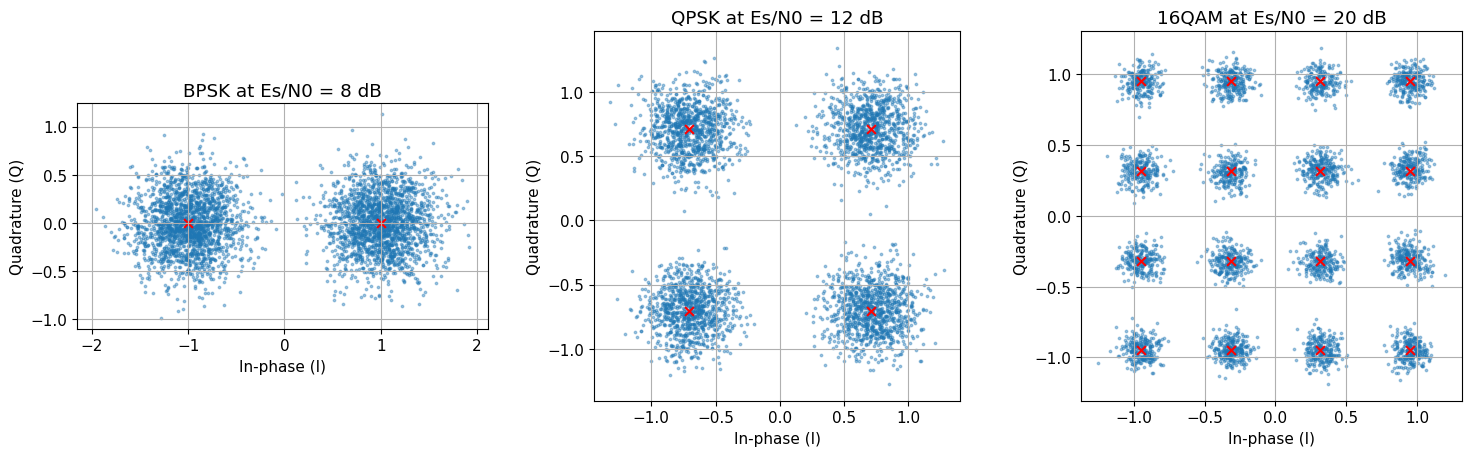

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name, snr in zip(axs, SCHEMES, [8, 12, 20]):
    k = CONST[name][1]
    bits = rng.integers(0, 2, 4000 * k)
    tx, _ = bits_to_symbols(bits, name)
    rx = awgn(tx, snr)
    ax.scatter(rx.real, rx.imag, s=3, alpha=0.4)
    ax.scatter(CONST[name][0].real, CONST[name][0].imag, c="red", s=40, marker="x")
    ax.set_title(f"{name} at Es/N0 = {snr} dB")
    ax.set_xlabel("In-phase (I)"); ax.set_ylabel("Quadrature (Q)"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## Part 2: Simulated vs theoretical BER (Unit 4.2), x-axis is Eb/N0
Simulated points should sit on the theory lines. For 16-QAM the plot shows both the common approximation and the exact expression, so you can see how large the approximation error is.

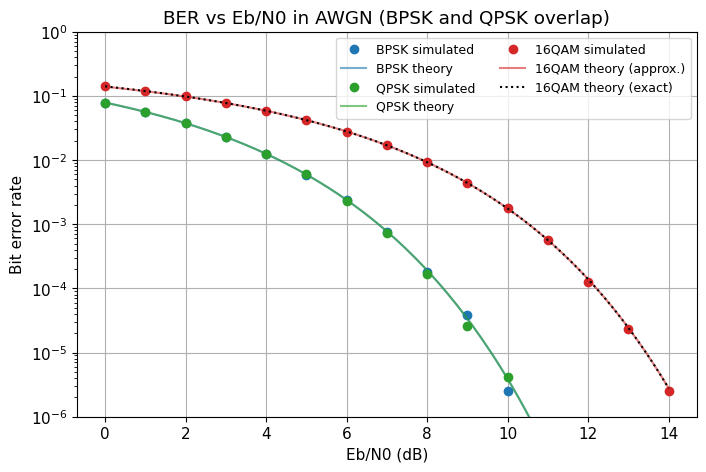

16-QAM, points with >= 100 simulated errors (statistically reliable):
 EbN0_dB  errors  sim_BER   theory    exact  approx_vs_exact_%  sim_vs_exact_%
       0  169091    0.141    0.139    0.141              -1.29         -0.0514
       1  142560    0.119    0.118    0.119             -0.548          -0.166
       2  117715   0.0981   0.0976   0.0977             -0.187           0.362
       3   92830   0.0774   0.0774   0.0775            -0.0486          -0.122
       4   70485   0.0587   0.0586   0.0586           -0.00901           0.194
       5   49944   0.0416   0.0419   0.0419           -0.00109          -0.651
       6   33083   0.0276   0.0279   0.0279          -7.72e-05           -1.08
       7   20418    0.017    0.017    0.017          -2.78e-06           0.284
       8   11063  0.00922  0.00925  0.00925          -4.28e-08          -0.303
       9    5263  0.00439  0.00439  0.00439          -2.25e-10          -0.103
      10    2113  0.00176  0.00175  0.00175          -3.09e-1

In [ ]:
ebn0_range = np.arange(0, 15, 1.0)
colors = {"BPSK": "tab:blue", "QPSK": "tab:green", "16QAM": "tab:red"}
part2 = []
plt.figure()
for name in SCHEMES:
    k = CONST[name][1]
    errs = [sim_errors_esn0(name, e + 10 * np.log10(k), 1_200_000) for e in ebn0_range]
    sim = np.array([e / n for e, n in errs]); ecount = np.array([e for e, _ in errs])
    mask = sim > 0
    plt.semilogy(ebn0_range[mask], sim[mask], "o", color=colors[name], label=f"{name} simulated")
    fine = np.linspace(0, 14, 200)
    plt.semilogy(fine, ber_theory(name, fine), "-", color=colors[name], alpha=0.6,
                 label=f"{name} theory" + (" (approx.)" if name == "16QAM" else ""))
    if name == "16QAM":
        plt.semilogy(fine, ber_theory_16qam_exact(fine), ":", color="k", label="16QAM theory (exact)")
    for e, s, c in zip(ebn0_range, sim, ecount):
        part2.append(dict(scheme=name, EbN0_dB=e, sim_BER=s, errors=c, theory=float(ber_theory(name, e)),
                          exact=float(ber_theory_16qam_exact(e)) if name == "16QAM" else np.nan))
plt.ylim(1e-6, 1)
plt.xlabel("Eb/N0 (dB)"); plt.ylabel("Bit error rate")
plt.title("BER vs Eb/N0 in AWGN (BPSK and QPSK overlap)")
plt.legend(ncol=2, fontsize=9); plt.show()

df2 = pd.DataFrame(part2)
q = df2[(df2.scheme == "16QAM") & (df2.errors >= 100)].copy()
q["approx_vs_exact_%"] = 100 * (q.theory - q.exact) / q.exact
q["sim_vs_exact_%"] = 100 * (q.sim_BER - q.exact) / q.exact
print("16-QAM, points with >= 100 simulated errors (statistically reliable):")
print(q[["EbN0_dB", "errors", "sim_BER", "theory", "exact", "approx_vs_exact_%", "sim_vs_exact_%"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3g}"))

## Part 3: Adaptive modulation (Units 2.3 and 4.2), x-axis is Es/N0
**Idea:** pick the highest-order scheme whose BER stays below a target at the current channel SNR.

**Switching thresholds** come from the **theoretical** BER (smallest Es/N0 at which BER <= target). The **simulated** BER is then used to check whether the target really is met. Both are reported.

In [ ]:
TARGET_BER = 1e-3
snr_grid = np.arange(-5, 35, 0.05)
THR = {}
for name in SCHEMES:
    k = CONST[name][1]
    ber = ber_theory(name, snr_grid - 10 * np.log10(k))
    THR[name] = snr_grid[np.argmax(ber <= TARGET_BER)]
thr_exact_16 = snr_grid[np.argmax(ber_theory_16qam_exact(snr_grid - 10 * np.log10(4)) <= TARGET_BER)]
print(f"Switching thresholds for target BER = {TARGET_BER:g} (Es/N0 in dB):")
for name in SCHEMES:
    print(f"  use {name:6s} when Es/N0 >= {THR[name]:5.2f} dB   (nominal {CONST[name][1]} bit/s/Hz)")
print(f"(16-QAM threshold using the exact BER expression instead of the approximation: {thr_exact_16:.2f} dB)")

def select_scheme(snr_db, margin_db=0.0):
    chosen = "BPSK"                         # fallback in deep fade (target may not be met)
    for s in SCHEMES:
        if snr_db - margin_db >= THR[s]:
            chosen = s
    return chosen

Switching thresholds for target BER = 0.001 (Es/N0 in dB):
  use BPSK   when Es/N0 >=  6.80 dB   (nominal 1 bit/s/Hz)
  use QPSK   when Es/N0 >=  9.80 dB   (nominal 2 bit/s/Hz)
  use 16QAM  when Es/N0 >= 16.55 dB   (nominal 4 bit/s/Hz)
(16-QAM threshold using the exact BER expression instead of the approximation: 16.55 dB)


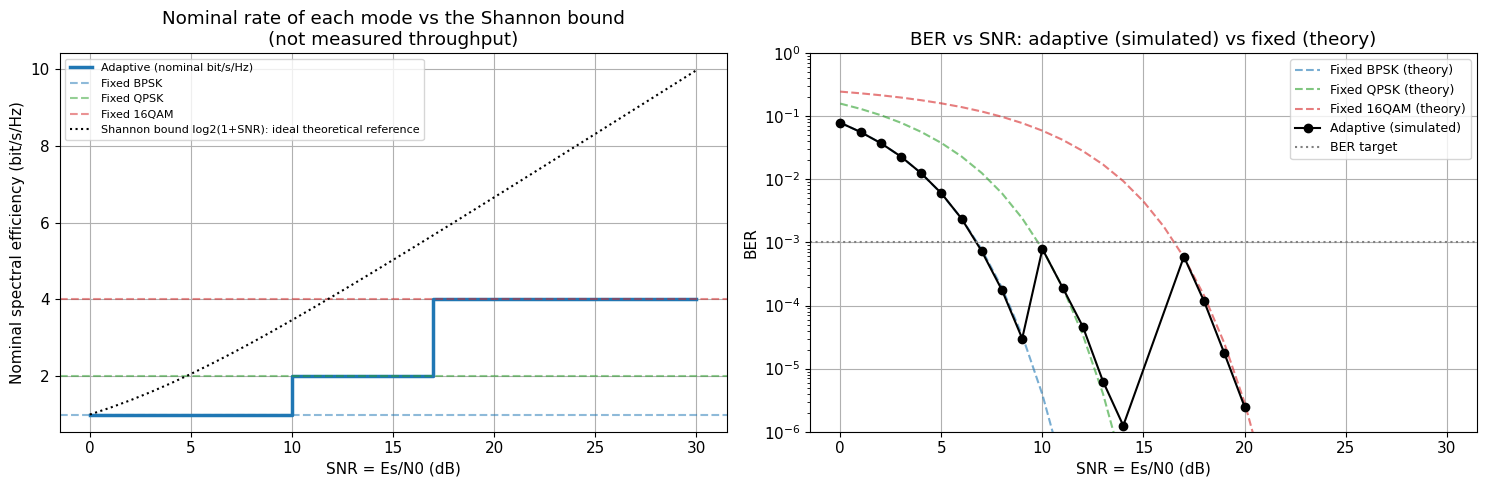

In [ ]:
snr_axis = np.arange(0, 31, 1.0)
NBITS_AD = 800_000
rows = []
for snr in snr_axis:
    s = select_scheme(snr)
    k = CONST[s][1]
    e, n = sim_errors_esn0(s, snr, NBITS_AD)
    p = e / n
    half = 1.96 * np.sqrt(max(p * (1 - p), 1e-12) / n)
    if snr < THR["BPSK"]:
        verdict = "unattainable (below BPSK threshold)"
    elif p <= TARGET_BER:
        verdict = "meets"
    elif p - half <= TARGET_BER:
        verdict = "marginal (within statistical noise)"
    else:
        verdict = "MISSES"
    ebn0 = snr - 10 * np.log10(k)
    rows.append(dict(EsN0_dB=snr, scheme=s, EbN0_dB=round(ebn0, 2), bits=n, errors=e, sim_BER=p,
                     theory_BER=float(ber_theory(s, ebn0)),
                     exact_BER=float(ber_theory_16qam_exact(ebn0)) if s == "16QAM" else np.nan,
                     target_check=verdict))
df3 = pd.DataFrame(rows)
ad_ber = df3.sim_BER.values
ad_se = np.array([CONST[s][1] for s in df3.scheme])

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].step(snr_axis, ad_se, where="post", lw=2.5, label="Adaptive (nominal bit/s/Hz)")
for name in SCHEMES:
    axs[0].axhline(CONST[name][1], ls="--", alpha=0.5, color=colors[name], label=f"Fixed {name}")
cap = np.log2(1 + 10 ** (snr_axis / 10))
axs[0].plot(snr_axis, cap, "k:", label="Shannon bound log2(1+SNR): ideal theoretical reference")
axs[0].set_xlabel("SNR = Es/N0 (dB)"); axs[0].set_ylabel("Nominal spectral efficiency (bit/s/Hz)")
axs[0].set_title("Nominal rate of each mode vs the Shannon bound\n(not measured throughput)"); axs[0].legend(fontsize=8)
for name in SCHEMES:
    k = CONST[name][1]
    axs[1].semilogy(snr_axis, ber_theory(name, snr_axis - 10 * np.log10(k)), "--", color=colors[name], alpha=0.6,
                    label=f"Fixed {name} (theory)")
m = ad_ber > 0
axs[1].semilogy(snr_axis[m], ad_ber[m], "ko-", label="Adaptive (simulated)")
axs[1].axhline(TARGET_BER, color="gray", ls=":", label="BER target")
axs[1].set_ylim(1e-6, 1); axs[1].set_xlabel("SNR = Es/N0 (dB)"); axs[1].set_ylabel("BER")
axs[1].set_title("BER vs SNR: adaptive (simulated) vs fixed (theory)"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

### Does the simulated BER actually meet the 10^-3 target?
The table lists, for each SNR, the chosen scheme, the simulated BER with its error count, and the theoretical values. Expected reasons for deviations:
* **Thresholds sit exactly where theory = target**, so right at a switching point the true BER is about 10^-3 and a finite simulation will land slightly above or below it by chance (with ~800 errors the relative standard deviation is about 3.5 percent).
* **Few errors at low BER:** below roughly 10^-5 a run of 800,000 bits contains only a handful of errors (or none), so those BER values are noisy and zero is plotted as missing.
* **16-QAM approximation:** the threshold uses the nearest-neighbour approximation. Near the 10^-3 target it is practically identical to the exact expression (the exact threshold printed above matches), so it does not affect the switching points; it deviates by about 1 percent only at very low Eb/N0, where it is not used. Differences between simulation and theory in the Part 2 table are therefore mostly statistical (for example about 150 errors gives roughly 8 percent random scatter).
* **Below the BPSK threshold** (Es/N0 < 6.8 dB) the target cannot be met by any scheme; BPSK is used as a fallback and these points are labelled "unattainable", not counted as failures of the adaptive rule.

In [ ]:
show = df3.copy()
for c in ["sim_BER", "theory_BER", "exact_BER"]:
    show[c] = show[c].map(lambda v: "" if pd.isna(v) else f"{v:.2e}")
print(show.to_string(index=False))
n_miss = int((df3.target_check == "MISSES").sum()); n_marg = int(df3.target_check.str.startswith("marginal").sum())
n_unatt = int(df3.target_check.str.startswith("unattainable").sum()); n_meet = int((df3.target_check == "meets").sum())
print(f"\nSNR points: {len(df3)} | meets target: {n_meet} | marginal: {n_marg} | misses: {n_miss} | "
      f"unattainable (below BPSK threshold, no scheme can reach the target): {n_unatt}")

 EsN0_dB scheme  EbN0_dB   bits  errors  sim_BER theory_BER exact_BER                        target_check
     0.0   BPSK     0.00 800000   63152 7.89e-02   7.86e-02           unattainable (below BPSK threshold)
     1.0   BPSK     1.00 800000   45035 5.63e-02   5.63e-02           unattainable (below BPSK threshold)
     2.0   BPSK     2.00 800000   30044 3.76e-02   3.75e-02           unattainable (below BPSK threshold)
     3.0   BPSK     3.00 800000   18385 2.30e-02   2.29e-02           unattainable (below BPSK threshold)
     4.0   BPSK     4.00 800000   10008 1.25e-02   1.25e-02           unattainable (below BPSK threshold)
     5.0   BPSK     5.00 800000    4816 6.02e-03   5.95e-03           unattainable (below BPSK threshold)
     6.0   BPSK     6.00 800000    1906 2.38e-03   2.39e-03           unattainable (below BPSK threshold)
     7.0   BPSK     7.00 800000     579 7.24e-04   7.73e-04                                         meets
     8.0   BPSK     8.00 800000     140 1.75e-

## Part 4: AI detector vs conventional detectors (extension to Unit 3.3)

A small **MLP neural network** classifies each received I/Q point into one of the 16-QAM symbols. The point of this section is a **fair** comparison, so:

* **Identical test signals:** for every Eb/N0 one batch of received symbols is generated once and given to *all* detectors. Test data are generated with a different random seed from the training data and were never seen in training.
* **Three conventional/AI detectors are compared:**
  1. *ML, ideal constellation* - minimum distance to the nominal 16-QAM points (what a receiver that ignores distortion does).
  2. *ML, distortion-aware* - minimum distance to the **distorted** points. When the noise is added after the distortion, this is the optimal detector, so it is the fair reference for AI.
  3. *AI (MLP)* - learns the mapping from labelled training data, with no explicit model of the distortion.
* **Experiment A (pure AWGN):** minimum distance is already optimal, so the AI is **not expected to win**; matching it is the best it can do.
* **Experiment B (AWGN + power-amplifier distortion):** the ideal-constellation detector is mismatched. The question is whether the AI can recover the loss *without being told the distortion*. A distortion-aware ML detector shows the best achievable result. An AI trained on distortion-free data is also tested, to show that the AI depends on training data matching the channel.

In [ ]:
def pa_distortion(x, comp=0.12, phi=0.12):
    """Simple nonlinear amplifier: gain compression + power-dependent phase rotation."""
    p = np.abs(x) ** 2
    return x * np.exp(1j * phi * p) / (1 + comp * p)

def make_data(name, n, esn0_db_low, esn0_db_high, impair):
    pts = CONST[name][0]
    idx = rng.integers(0, len(pts), n)
    tx = pts[idx]
    if impair:
        tx = pa_distortion(tx)
    esn0 = rng.uniform(esn0_db_low, esn0_db_high, n)       # mixed SNRs for training
    rx = awgn(tx, esn0)
    return rx, idx

def feats(rx):
    return np.c_[rx.real, rx.imag]

def train_ai(name, impair, n=150_000):
    rx, idx = make_data(name, n, 8, 30, impair)           # training Es/N0 range: 8-30 dB
    clf = MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", max_iter=80,
                        early_stopping=True, random_state=0)
    clf.fit(feats(rx), idx)
    return clf

rng = np.random.default_rng(0)                             # TRAINING seed
print("Training AI detector on distortion-free AWGN data ...")
ai_awgn = train_ai("16QAM", impair=False)
print("Training AI detector on AWGN + PA distortion data ...")
ai_pa = train_ai("16QAM", impair=True)
print("Done")

Training AI detector on distortion-free AWGN data ...
Training AI detector on AWGN + PA distortion data ...
Done


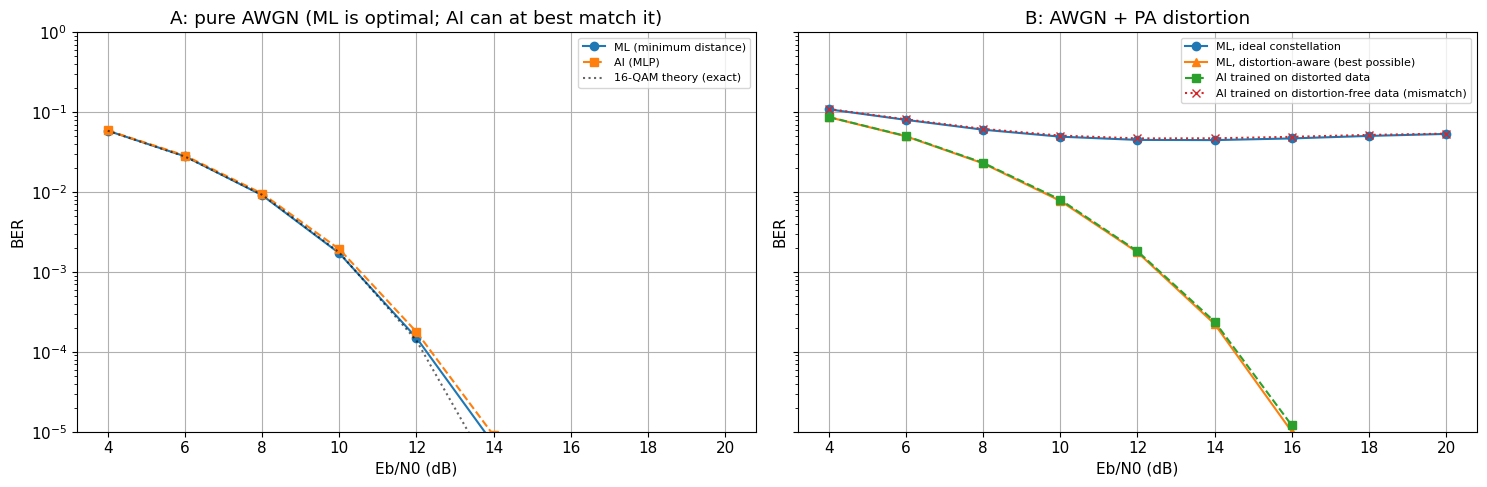

Experiment A: bit errors out of 1000000 bits per point (same test signals for both detectors)
 EbN0_dB    bits  ML_ideal  ML_aware  AI_trained_awgn
     4.0 1000000     58617     58617            59106
     6.0 1000000     28062     28062            28667
     8.0 1000000      9138      9138             9584
    10.0 1000000      1716      1716             1931
    12.0 1000000       150       150              178
    14.0 1000000         7         7                9
    16.0 1000000         0         0                0
    18.0 1000000         0         0                0
    20.0 1000000         0         0                0

Experiment B: bit errors out of 1000000 bits per point (same test signals for all detectors)
 EbN0_dB    bits  ML_ideal  ML_aware  AI_trained_with_PA  AI_trained_awgn_only
     4.0 1000000    108638     86719               87070                109573
     6.0 1000000     80163     49918               50389                 81380
     8.0 1000000     60402     2287

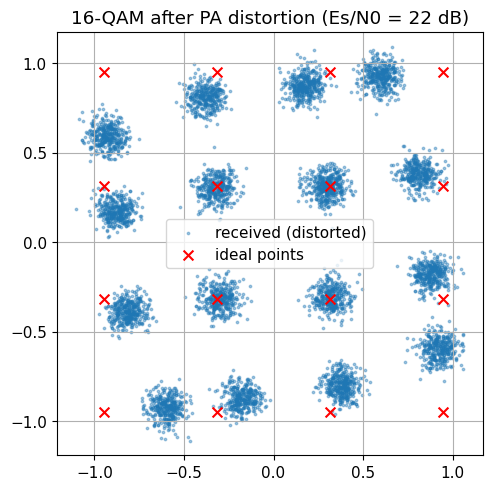

In [ ]:
def eval_all(ai_models, impair, ebn0_list, nsym=250_000):
    """Every detector sees the SAME received samples at each Eb/N0."""
    name = "16QAM"; pts = CONST[name][0]
    pts_rx = pa_distortion(pts) if impair else pts
    rows = []
    for e in ebn0_list:
        esn0 = e + 10 * np.log10(4)
        idx = rng.integers(0, 16, nsym)
        rx = awgn(pts_rx[idx], esn0)                        # one batch, shared by all detectors
        b_true = idx_to_bits(idx, name)
        row = dict(EbN0_dB=e, bits=len(b_true))
        row["ML_ideal"] = int(np.sum(idx_to_bits(ml_detect(rx, name), name) != b_true))
        row["ML_aware"] = int(np.sum(idx_to_bits(ml_detect(rx, name, pts=pts_rx), name) != b_true))
        for label, clf in ai_models.items():
            row[label] = int(np.sum(idx_to_bits(clf.predict(feats(rx)), name) != b_true))
        rows.append(row)
    return pd.DataFrame(rows)

rng = np.random.default_rng(2026)                           # TEST seed (different from training)
ebn0_ai = np.arange(4, 21, 2.0)
dfA = eval_all({"AI_trained_awgn": ai_awgn}, False, ebn0_ai)
dfB = eval_all({"AI_trained_with_PA": ai_pa, "AI_trained_awgn_only": ai_awgn}, True, ebn0_ai)

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
def ber_of(df, col):
    return (df[col] / df.bits).values
ax = axs[0]
for col, lab, st in [("ML_ideal", "ML (minimum distance)", "o-"), ("AI_trained_awgn", "AI (MLP)", "s--")]:
    b = ber_of(dfA, col); ax.semilogy(ebn0_ai[b > 0], b[b > 0], st, label=lab)
ax.semilogy(ebn0_ai, ber_theory_16qam_exact(ebn0_ai), "k:", alpha=0.6, label="16-QAM theory (exact)")
ax.set_title("A: pure AWGN (ML is optimal; AI can at best match it)")
ax = axs[1]
for col, lab, st in [("ML_ideal", "ML, ideal constellation", "o-"), ("ML_aware", "ML, distortion-aware (best possible)", "^-"),
                     ("AI_trained_with_PA", "AI trained on distorted data", "s--"),
                     ("AI_trained_awgn_only", "AI trained on distortion-free data (mismatch)", "x:")]:
    b = ber_of(dfB, col); ax.semilogy(ebn0_ai[b > 0], b[b > 0], st, label=lab)
ax.set_title("B: AWGN + PA distortion")
for ax in axs:
    ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel("BER"); ax.set_ylim(1e-5, 1); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Experiment A: bit errors out of", int(dfA.bits[0]), "bits per point (same test signals for both detectors)")
print(dfA.to_string(index=False))
print("\nExperiment B: bit errors out of", int(dfB.bits[0]), "bits per point (same test signals for all detectors)")
print(dfB.to_string(index=False))
print("\nCaution: points with fewer than ~100 errors have large statistical uncertainty.")

rx_demo, _ = make_data("16QAM", 6000, 22, 22, True)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(rx_demo.real, rx_demo.imag, s=3, alpha=0.4, label="received (distorted)")
plt.scatter(CONST["16QAM"][0].real, CONST["16QAM"][0].imag, c="red", marker="x", s=50, label="ideal points")
plt.title("16-QAM after PA distortion (Es/N0 = 22 dB)"); plt.axis("equal"); plt.legend(); plt.show()

**How to read Part 4 (what you can and cannot claim):**
* In pure AWGN the ML detector is optimal, so the AI can at best equal it. Expect the AI to be equal or slightly worse (it only approximates the decision regions). A small deficit is the expected result, not a failure of the method, and the AI must not be described as better here.
* With distortion, the AI recovers most of the loss that the ideal-constellation detector suffers, **but a detector that knows the distortion does at least as well**. The AI's practical advantage is that it learns the mapping from data when the distortion is unknown or hard to model; its cost is the need for representative training data. The mismatched-training curve shows it does not generalise to impairments it was not trained on.
* So the AI is *not* better than conventional detection in general; it is useful when the conventional model does not describe the channel.

## Part 5: AI SNR estimator and closed-loop adaptive system

The receiver needs an SNR estimate to feed back to the transmitter. A short **QPSK pilot block** is sent, the **error vector magnitude (EVM)** of the decided symbols is computed, and a small regression model (gradient boosting) maps EVM to SNR. The regressor corrects the bias at low SNR, where decisions are partly wrong.

**Limitations to keep in mind:** the estimator is trained and tested on the *same simulated AWGN setup* (perfect synchronisation, unit transmit power, no fading, known pilot modulation). A low error here shows it works in that model; it does not show it would work in a real radio. The tests below therefore use many independent realisations and a few deliberate mismatches.

In [ ]:
PILOT_LEN = 256

def pilot_evm(snr_db_array, n=PILOT_LEN):
    """Simulate one QPSK pilot block per SNR value; return log10(EVM) feature."""
    B = len(snr_db_array)
    pts = CONST["QPSK"][0]
    idx = rng.integers(0, 4, (B, n))
    rx = awgn(pts[idx], np.asarray(snr_db_array)[:, None])
    det = ml_detect(rx.reshape(-1), "QPSK").reshape(B, n)
    evm = np.mean(np.abs(rx - pts[det]) ** 2, axis=1)
    return np.log10(evm)

rng = np.random.default_rng(1)                               # training seed
train_snr = rng.uniform(0, 32, 4000)
X_tr = pilot_evm(train_snr).reshape(-1, 1)
snr_est_model = GradientBoostingRegressor(random_state=0).fit(X_tr, train_snr)
print("Estimator trained on pilot blocks with true SNR uniform in [0, 32] dB")

Estimator trained on pilot blocks with true SNR uniform in [0, 32] dB


Estimator error over 40 independent realisations at each SNR (pilot length 256):
 true_SNR_dB  mean_error_dB  std_dB  RMSE_dB
         2.0         -0.088   0.359    0.370
         6.0         -0.032   0.316    0.318
        10.0         -0.010   0.259    0.259
        14.0          0.025   0.284    0.285
        18.0          0.016   0.266    0.266
        22.0          0.009   0.208    0.208
        26.0          0.002   0.291    0.291
        30.0         -0.019   0.248    0.249

OVERALL RMSE = 0.28 dB (in-distribution: same simulation setup as training)


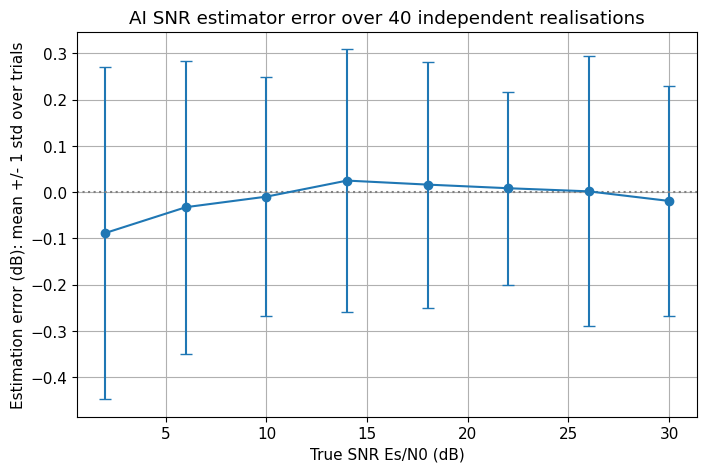


Sensitivity checks (same trained model):
  pilot length    64: RMSE = 0.60 dB
  pilot length   256: RMSE = 0.29 dB   <- training length
  pilot length  1024: RMSE = 0.17 dB
  SNR outside the training range (true -> mean estimate): 34 -> 31.8, 36 -> 31.8, 38 -> 31.8, 40 -> 31.8 dB  (the model cannot extrapolate beyond 32 dB)


In [ ]:
# (1) Many independent noise realisations per SNR, each with its own seed
N_TRIALS = 40
eval_snr = np.arange(2, 31, 4.0)
err = np.zeros((N_TRIALS, len(eval_snr)))
for t in range(N_TRIALS):
    rng = np.random.default_rng(10_000 + t)                  # independent realisation
    est = snr_est_model.predict(pilot_evm(eval_snr).reshape(-1, 1))
    err[t] = est - eval_snr
bias, std, rmse_pt = err.mean(0), err.std(0), np.sqrt((err ** 2).mean(0))
rmse_all = float(np.sqrt((err ** 2).mean()))
tbl = pd.DataFrame(dict(true_SNR_dB=eval_snr, mean_error_dB=bias, std_dB=std, RMSE_dB=rmse_pt))
print(f"Estimator error over {N_TRIALS} independent realisations at each SNR (pilot length {PILOT_LEN}):")
print(tbl.round(3).to_string(index=False))
print(f"\nOVERALL RMSE = {rmse_all:.2f} dB (in-distribution: same simulation setup as training)")

plt.figure()
plt.errorbar(eval_snr, bias, yerr=std, fmt="o-", capsize=4)
plt.axhline(0, color="gray", ls=":")
plt.xlabel("True SNR Es/N0 (dB)"); plt.ylabel("Estimation error (dB): mean +/- 1 std over trials")
plt.title(f"AI SNR estimator error over {N_TRIALS} independent realisations"); plt.show()

# (2) Deliberate mismatches
print("\nSensitivity checks (same trained model):")
for n_p in [64, 256, 1024]:
    e2 = []
    for t in range(N_TRIALS):
        rng = np.random.default_rng(20_000 + t)
        e2.append(snr_est_model.predict(pilot_evm(eval_snr, n=n_p).reshape(-1, 1)) - eval_snr)
    print(f"  pilot length {n_p:5d}: RMSE = {np.sqrt(np.mean(np.square(e2))):.2f} dB"
          + ("   <- training length" if n_p == PILOT_LEN else ""))
rng = np.random.default_rng(30_000)
hi_snr = np.array([34.0, 36.0, 38.0, 40.0])
est_hi = snr_est_model.predict(pilot_evm(np.repeat(hi_snr, 20)).reshape(-1, 1)).reshape(4, 20).mean(1)
print("  SNR outside the training range (true -> mean estimate):",
      ", ".join(f"{a:.0f} -> {b:.1f}" for a, b in zip(hi_snr, est_hi)),
      "dB  (the model cannot extrapolate beyond 32 dB)")

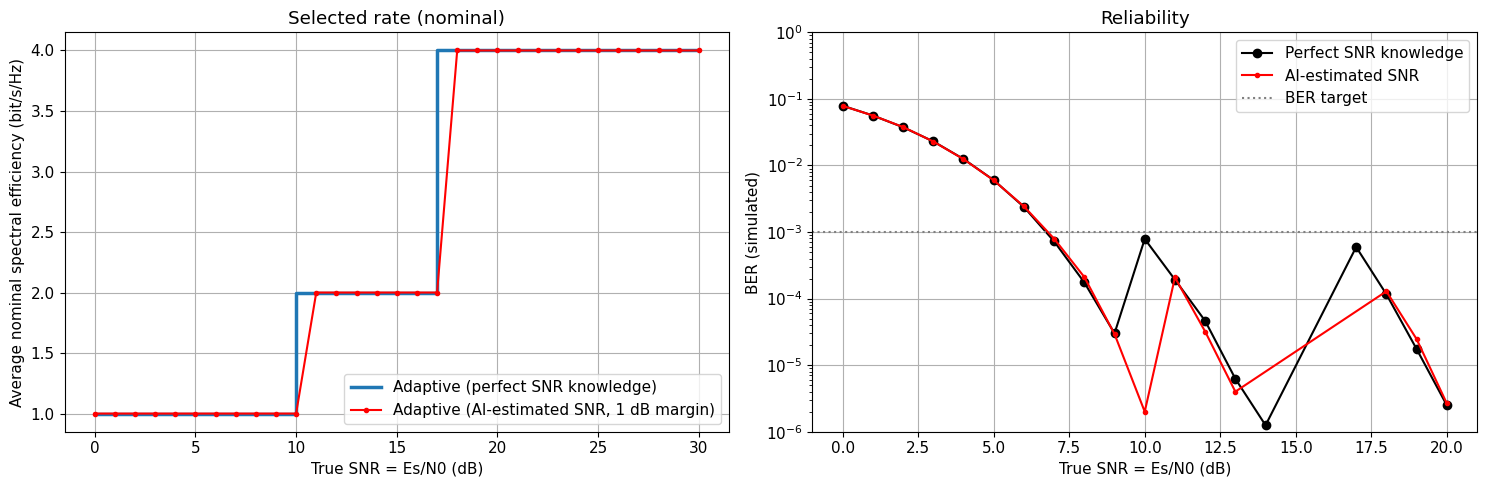

Among SNR points >= BPSK threshold (24 points):
  perfect knowledge : BER <= target at 24 points
  AI-estimated SNR  : BER <= target at 24 points


In [ ]:
MARGIN_DB = 1.0
REP = 10
rng = np.random.default_rng(40_000)
rows = []
for snr in snr_axis:
    est_snr = snr_est_model.predict(pilot_evm(np.full(REP, snr)).reshape(-1, 1))
    chosen = [select_scheme(e, MARGIN_DB) for e in est_snr]
    res = [sim_errors_esn0(s, snr, 150_000) for s in chosen]
    rows.append((np.mean([e / n for e, n in res]), np.mean([CONST[s][1] for s in chosen])))
ai_ad_ber = np.array([r[0] for r in rows]); ai_ad_se = np.array([r[1] for r in rows])

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].step(snr_axis, ad_se, where="post", lw=2.5, label="Adaptive (perfect SNR knowledge)")
axs[0].plot(snr_axis, ai_ad_se, "r.-", label=f"Adaptive (AI-estimated SNR, {MARGIN_DB:g} dB margin)")
axs[0].set_xlabel("True SNR = Es/N0 (dB)"); axs[0].set_ylabel("Average nominal spectral efficiency (bit/s/Hz)")
axs[0].set_title("Selected rate (nominal)"); axs[0].legend()
m1 = ad_ber > 0; m2 = ai_ad_ber > 0
axs[1].semilogy(snr_axis[m1], ad_ber[m1], "ko-", label="Perfect SNR knowledge")
axs[1].semilogy(snr_axis[m2], ai_ad_ber[m2], "r.-", label="AI-estimated SNR")
axs[1].axhline(TARGET_BER, color="gray", ls=":", label="BER target")
axs[1].set_ylim(1e-6, 1); axs[1].set_xlabel("True SNR = Es/N0 (dB)"); axs[1].set_ylabel("BER (simulated)")
axs[1].set_title("Reliability"); axs[1].legend()
plt.tight_layout(); plt.show()

above = snr_axis >= THR["BPSK"]
print(f"Among SNR points >= BPSK threshold ({above.sum()} points):")
print(f"  perfect knowledge : BER <= target at {(ad_ber[above] <= TARGET_BER).sum()} points")
print(f"  AI-estimated SNR  : BER <= target at {(ai_ad_ber[above] <= TARGET_BER).sum()} points")

## Summary of results
Copy these from **your own run** into the report (numbers vary slightly between runs because the simulation is random).

In [ ]:
print("Switching thresholds (target BER = %g, from theory):" % TARGET_BER)
for name in SCHEMES:
    print(f"  {name:6s} from Es/N0 >= {THR[name]:5.2f} dB  -> nominal {CONST[name][1]} bit/s/Hz")
print(f"\nTarget check of simulated adaptive BER (of {len(df3)} SNR points): meets {n_meet}, marginal {n_marg}, "
      f"misses {n_miss}, unattainable (below BPSK threshold) {n_unatt}")
print("\nPart 4, Experiment B (16-QAM with PA distortion): BER by detector")
sB = dfB.copy()
for c in ["ML_ideal", "ML_aware", "AI_trained_with_PA", "AI_trained_awgn_only"]:
    sB[c] = (dfB[c] / dfB.bits).map(lambda v: f"{v:.2e}")
print(sB[["EbN0_dB", "ML_ideal", "ML_aware", "AI_trained_with_PA", "AI_trained_awgn_only"]].to_string(index=False))
print(f"\nSNR estimator: overall RMSE = {rmse_all:.2f} dB over {N_TRIALS} independent realisations (simulated AWGN only)")

Switching thresholds (target BER = 0.001, from theory):
  BPSK   from Es/N0 >=  6.80 dB  -> nominal 1 bit/s/Hz
  QPSK   from Es/N0 >=  9.80 dB  -> nominal 2 bit/s/Hz
  16QAM  from Es/N0 >= 16.55 dB  -> nominal 4 bit/s/Hz

Target check of simulated adaptive BER (of 31 SNR points): meets 24, marginal 0, misses 0, unattainable (below BPSK threshold) 7

Part 4, Experiment B (16-QAM with PA distortion): BER by detector
 EbN0_dB ML_ideal ML_aware AI_trained_with_PA AI_trained_awgn_only
     4.0 1.09e-01 8.67e-02           8.71e-02             1.10e-01
     6.0 8.02e-02 4.99e-02           5.04e-02             8.14e-02
     8.0 6.04e-02 2.29e-02           2.33e-02             6.18e-02
    10.0 4.94e-02 7.76e-03           8.05e-03             5.10e-02
    12.0 4.50e-02 1.76e-03           1.82e-03             4.70e-02
    14.0 4.47e-02 2.23e-04           2.39e-04             4.71e-02
    16.0 4.70e-02 1.00e-05           1.20e-05             4.92e-02
    18.0 5.05e-02 0.00e+00           0.00e+00 

## Notes for your report / viva
* **Why adapt?** Shannon: C = B log2(1 + SNR). Capacity grows with SNR, so a fixed scheme either wastes capacity at high SNR or fails at low SNR. The Shannon curve is an *ideal theoretical bound*, not a measured throughput of these modes.
* **Es/N0 vs Eb/N0:** modes with more bits per symbol have lower Eb/N0 at the same Es/N0 (Eb/N0 = Es/N0 - 10 log10 k), which is why BER is compared against Eb/N0 while the selector uses Es/N0.
* **Why Gray coding?** Adjacent symbols differ in one bit, so a likely symbol error causes only one bit error.
* **AI versus ML:** for equiprobable symbols in AWGN, minimum-distance detection is optimal. The AI is worth studying only when the channel has effects the conventional model ignores. Even then, a detector that knows the impairment is the benchmark; the AI's value is that it can learn the impairment from data.
* **Not implemented (state this explicitly):** source coding, channel coding, ISI channel / equalizer, pulse shaping, fading, synchronisation and hardware. These appear in the architecture diagram as the complete system and are possible future work (for example Hamming-coded adaptive modulation, Unit 5.1; non-coherent detection, the self-learning topic in Unit 3.4).
* **Estimator limitation:** it is evaluated only on simulated AWGN data with the same structure as its training data, so its low RMSE is a result about this simulation, not about real wireless channels.